### Mutation Combination Effect

#### First check co-occurrance pattern of mutations


In [3]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")


In [13]:
df_biotype = pd.read_csv("treeWAS_phen_dates.csv")
df_snps = pd.read_csv("phen_scores_dates.csv")
df_snps = df_snps.rename(columns={"Unnamed: 0": "Accession"})

df_all = pd.merge(df_biotype, df_snps, on="Accession")
# SNP_818はFCSの直後でアライメントが難しく、variableになっているためのぞく
df_all = df_all.drop(columns=["SNP_818"])
snp_cols = [col for col in df_all.columns if col.startswith("SNP_")]

df_all["biotype"] = df_all["biotype"].astype(int)
for col in snp_cols:
    df_all[col] = df_all[col].astype(int)

df_all

,Accession,biotype,SNP_791,SNP_809,SNP_811,SNP_813,SNP_814,SNP_826,SNP_1056,SNP_1072,SNP_1074,SNP_1078,SNP_1129,SNP_1133,SNP_1135,SNP_1160,SNP_1212,SNP_1363,SNP_1368
0,PQ416775.1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0
1,PX315748.1,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0
2,PX315749.1,1,1,1,0,0,1,0,1,1,0,0,0,0,0,0,0,1,0
3,PX315750.1,1,1,1,0,0,1,0,1,1,0,0,0,0,0,0,0,1,0
4,PX315751.1,1,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,FJ917521.1,1,1,1,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0
116,FJ917522.1,0,1,1,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0
117,FJ917535.1,1,1,1,1,0,0,0,1,1,0,0,1,0,0,0,0,0,1
118,FJ917523.1,1,1,1,1,1,0,0,1,1,0,0,0,1,0,0,0,0,0


In [14]:
# values count for each SNP
for col in snp_cols:
    print(f"{col} value counts:")
    print(df_all[col].value_counts())
    print()

SNP_791 value counts:
SNP_791
0    83
1    37
Name: count, dtype: int64

SNP_809 value counts:
SNP_809
0    66
1    54
Name: count, dtype: int64

SNP_811 value counts:
SNP_811
0    100
1     20
Name: count, dtype: int64

SNP_813 value counts:
SNP_813
0    115
1      5
Name: count, dtype: int64

SNP_814 value counts:
SNP_814
0    91
1    29
Name: count, dtype: int64

SNP_826 value counts:
SNP_826
0    112
1      8
Name: count, dtype: int64

SNP_1056 value counts:
SNP_1056
1    70
0    50
Name: count, dtype: int64

SNP_1072 value counts:
SNP_1072
0    61
1    59
Name: count, dtype: int64

SNP_1074 value counts:
SNP_1074
0    114
1      6
Name: count, dtype: int64

SNP_1078 value counts:
SNP_1078
0    120
Name: count, dtype: int64

SNP_1129 value counts:
SNP_1129
0    111
1      9
Name: count, dtype: int64

SNP_1133 value counts:
SNP_1133
0    95
1    25
Name: count, dtype: int64

SNP_1135 value counts:
SNP_1135
0    93
1    27
Name: count, dtype: int64

SNP_1160 value counts:
SNP_1160
0 

In [15]:
summary_rows = []
for col in snp_cols:
    overall_rate = df_all[col].mean()
    fip_rate = df_all.loc[df_all["biotype"] == 1, col].mean()
    fecv_rate = df_all.loc[df_all["biotype"] == 0, col].mean()
    summary_rows.append({
        "SNP": col,
        "overall_positive_rate": overall_rate,
        "biotype_1_positive_rate": fip_rate,
        "biotype_0_positive_rate": fecv_rate,
    })

summary_df = pd.DataFrame(summary_rows).sort_values("overall_positive_rate", ascending=False)
summary_df


,SNP,overall_positive_rate,biotype_1_positive_rate,biotype_0_positive_rate
6,SNP_1056,0.583333,0.800000,0.28
7,SNP_1072,0.491667,0.828571,0.02
1,SNP_809,0.450000,0.542857,0.32
0,SNP_791,0.308333,0.414286,0.16
4,SNP_814,0.241667,0.414286,0.00
15,SNP_1363,0.225000,0.357143,0.04
12,SNP_1135,0.225000,0.300000,0.12
11,SNP_1133,0.208333,0.342857,0.02
16,SNP_1368,0.175000,0.285714,0.02
2,SNP_811,0.166667,0.271429,0.02


#### Vizualize co-occurrance pattern of two mutatoins

- left: number of samples when two mutations are both 1 at the same time
- right: Jaccard index = number of co-occuranace / number of samples at least one is 1
- bottom: number of co-occurrance by biotype


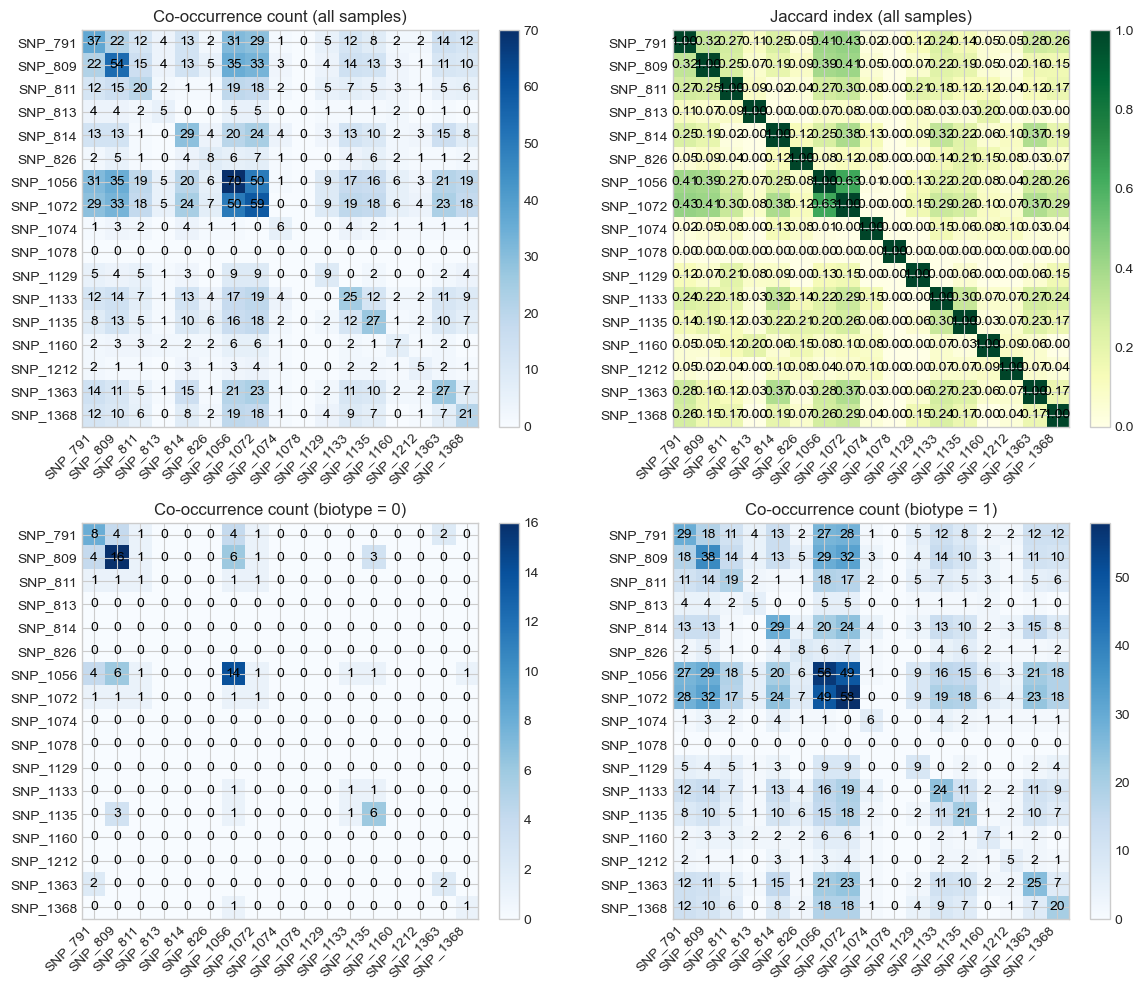

In [16]:
def build_pairwise_matrices(df, feature_cols):
    count_mat = pd.DataFrame(0.0, index=feature_cols, columns=feature_cols)
    jaccard_mat = pd.DataFrame(0.0, index=feature_cols, columns=feature_cols)

    for a in feature_cols:
        xa = df[a].astype(bool)
        count_mat.loc[a, a] = xa.sum()
        jaccard_mat.loc[a, a] = 1.0

    for a, b in itertools.combinations(feature_cols, 2):
        xa = df[a].astype(bool)
        xb = df[b].astype(bool)
        inter = (xa & xb).sum()
        union = (xa | xb).sum()
        jaccard = inter / union if union else np.nan

        count_mat.loc[a, b] = count_mat.loc[b, a] = inter
        jaccard_mat.loc[a, b] = jaccard_mat.loc[b, a] = jaccard

    return count_mat, jaccard_mat


def draw_heatmap(ax, matrix, title, fmt=".0f", cmap="Blues"):
    values = matrix.to_numpy(dtype=float)
    im = ax.imshow(values, cmap=cmap, aspect="equal")
    ax.set_xticks(range(len(matrix.columns)))
    ax.set_yticks(range(len(matrix.index)))
    ax.set_xticklabels(matrix.columns, rotation=45, ha="right")
    ax.set_yticklabels(matrix.index)
    ax.set_title(title)

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            value = values[i, j]
            if np.isnan(value):
                label = "NA"
            else:
                label = format(value, fmt)
            ax.text(j, i, label, ha="center", va="center", color="black", fontsize=10)

    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)


count_all, jaccard_all = build_pairwise_matrices(df_all, snp_cols)
count_biotype0, _ = build_pairwise_matrices(df_all[df_all["biotype"] == 0], snp_cols)
count_biotype1, _ = build_pairwise_matrices(df_all[df_all["biotype"] == 1], snp_cols)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
draw_heatmap(axes[0, 0], count_all, "Co-occurrence count (all samples)")
draw_heatmap(axes[0, 1], jaccard_all, "Jaccard index (all samples)", fmt=".2f", cmap="YlGn")
draw_heatmap(axes[1, 0], count_biotype0, "Co-occurrence count (biotype = 0)")
draw_heatmap(axes[1, 1], count_biotype1, "Co-occurrence count (biotype = 1)")
plt.tight_layout()
plt.show()

In [19]:
pair_rows = []
for a, b in itertools.combinations(snp_cols, 2):
    mask_a = df_all[a] == 1
    mask_b = df_all[b] == 1
    n11 = int((mask_a & mask_b).sum())
    n10 = int((mask_a & ~mask_b).sum())
    n01 = int((~mask_a & mask_b).sum())
    n00 = int((~mask_a & ~mask_b).sum())
    biotype_1_rate_when_double_pos = df_all.loc[mask_a & mask_b, "biotype"].mean()
    pair_rows.append({
        "SNP_A": a,
        "SNP_B": b,
        "n11": n11,
        "n10": n10,
        "n01": n01,
        "n00": n00,
        "jaccard": jaccard_all.loc[a, b],
        "biotype_1_rate_when_double_positive": biotype_1_rate_when_double_pos,
    })

pair_summary_df = pd.DataFrame(pair_rows).sort_values(["n11", "jaccard"], ascending=False)
pair_summary_df.reset_index(drop=True, inplace=True)
pair_summary_df

,SNP_A,SNP_B,n11,n10,n01,n00,jaccard,biotype_1_rate_when_double_positive
0,SNP_1056,SNP_1072,50,20,9,41,0.632911,0.980000
1,SNP_809,SNP_1056,35,19,35,31,0.393258,0.828571
2,SNP_809,SNP_1072,33,21,26,40,0.412500,0.969697
3,SNP_791,SNP_1056,31,6,39,44,0.407895,0.870968
4,SNP_791,SNP_1072,29,8,30,53,0.432836,0.965517
...,...,...,...,...,...,...,...,...
131,SNP_1078,SNP_1368,0,0,21,99,0.000000,NaN
132,SNP_1129,SNP_1133,0,9,25,86,0.000000,NaN
133,SNP_1129,SNP_1160,0,9,7,104,0.000000,NaN
134,SNP_1129,SNP_1212,0,9,5,106,0.000000,NaN


#### Sample details depending of the combination of mutations

 - Check what combination of SNPs in each sample and how many of these were biotype = 1


In [20]:
combination_summary = (
    df_all.groupby(snp_cols, dropna=False)
    .agg(
        n_samples=("Accession", "size"),
        n_biotype_1=("biotype", "sum"),
        biotype_1_rate=("biotype", "mean"),
    )
    .reset_index()
    .sort_values(["n_samples", "biotype_1_rate"], ascending=[False, False])
)

combination_summary.reset_index(drop=True, inplace=True)
combination_summary

,SNP_791,SNP_809,SNP_811,SNP_813,SNP_814,SNP_826,SNP_1056,SNP_1072,SNP_1074,SNP_1078,SNP_1129,SNP_1133,SNP_1135,SNP_1160,SNP_1212,SNP_1363,SNP_1368,n_samples,n_biotype_1,biotype_1_rate
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,20,0,0.000000
1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,7,1,0.142857
2,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,7,0,0.000000
3,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,3,0.600000
4,1,1,1,0,0,0,1,1,0,0,1,0,0,0,0,0,1,4,4,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,1,1,1,0,0,0,1,1,0,0,0,1,0,0,0,1,1,1,1,1.000000
65,1,1,1,1,0,0,1,1,0,0,0,0,1,0,0,0,0,1,1,1.000000
66,1,1,1,1,0,0,1,1,0,0,0,1,0,0,0,0,0,1,1,1.000000
67,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0.000000


#### Association between SNP combinations and biotype

- First, check each SNP alone with logistic regression
- Next, check each co-occurring pair with Fisher's exact test
- Finally, test whether the pair has an interaction effect after adjusting for the main effects of all SNPs


In [21]:
import warnings

import statsmodels.api as sm
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import PerfectSeparationError


def fit_single_snp_logistic(df, feature, label_col="biotype"):
    tmp = df[[label_col, feature]].dropna().copy()
    y = tmp[label_col].astype(float)
    X = sm.add_constant(tmp[[feature]].astype(float), has_constant="add")

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            result = sm.GLM(y, X, family=sm.families.Binomial()).fit()

        coef = result.params[feature]
        se = result.bse[feature]
        return {
            "feature": feature,
            "status": "ok",
            "coef": coef,
            "odds_ratio": float(np.exp(coef)),
            "ci_low": float(np.exp(coef - 1.96 * se)),
            "ci_high": float(np.exp(coef + 1.96 * se)),
            "p_value": result.pvalues[feature],
            "n_positive": int(tmp[feature].sum()),
            "n_samples": len(tmp),
        }
    except (PerfectSeparationError, np.linalg.LinAlgError):
        return {
            "feature": feature,
            "status": "model_failed",
            "coef": np.nan,
            "odds_ratio": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "p_value": np.nan,
            "n_positive": int(tmp[feature].sum()),
            "n_samples": len(tmp),
        }


def fisher_for_double_positive(df, feat_a, feat_b, label_col="biotype"):
    double_pos = (df[feat_a] == 1) & (df[feat_b] == 1)
    case = df[label_col] == 1

    n11 = int((double_pos & case).sum())
    n10 = int((double_pos & ~case).sum())
    n01 = int((~double_pos & case).sum())
    n00 = int((~double_pos & ~case).sum())

    odds_ratio, p_value = fisher_exact([[n11, n10], [n01, n00]], alternative="two-sided")
    return {
        "SNP_A": feat_a,
        "SNP_B": feat_b,
        "n_double_positive": int(double_pos.sum()),
        "case_double_positive": n11,
        "control_double_positive": n10,
        "case_other": n01,
        "control_other": n00,
        "double_positive_case_rate": df.loc[double_pos, label_col].mean(),
        "fisher_odds_ratio": odds_ratio,
        "fisher_p_value": p_value,
    }


def fit_pair_interaction_logistic(df, feat_a, feat_b, feature_cols, label_col="biotype"):
    tmp = df[[label_col] + feature_cols].dropna().copy()
    inter_col = f"{feat_a}__x__{feat_b}"
    tmp[inter_col] = tmp[feat_a] * tmp[feat_b]

    if tmp[inter_col].nunique() < 2:
        return {
            "SNP_A": feat_a,
            "SNP_B": feat_b,
            "interaction": inter_col,
            "status": "no_variation",
            "coef_interaction": np.nan,
            "or_interaction": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "p_value": np.nan,
            "n_double_positive": int(tmp[inter_col].sum()),
        }

    y = tmp[label_col].astype(float)
    X = sm.add_constant(tmp[feature_cols + [inter_col]].astype(float), has_constant="add")

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            result = sm.GLM(y, X, family=sm.families.Binomial()).fit()

        coef = result.params[inter_col]
        se = result.bse[inter_col]
        return {
            "SNP_A": feat_a,
            "SNP_B": feat_b,
            "interaction": inter_col,
            "status": "ok",
            "coef_interaction": coef,
            "or_interaction": float(np.exp(coef)),
            "ci_low": float(np.exp(coef - 1.96 * se)),
            "ci_high": float(np.exp(coef + 1.96 * se)),
            "p_value": result.pvalues[inter_col],
            "aic": result.aic,
            "n_double_positive": int(tmp[inter_col].sum()),
        }
    except (PerfectSeparationError, np.linalg.LinAlgError):
        return {
            "SNP_A": feat_a,
            "SNP_B": feat_b,
            "interaction": inter_col,
            "status": "model_failed",
            "coef_interaction": np.nan,
            "or_interaction": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "p_value": np.nan,
            "aic": np.nan,
            "n_double_positive": int(tmp[inter_col].sum()),
        }


def summarize_four_groups(df, feat_a, feat_b, label_col="biotype"):
    tmp = df[[feat_a, feat_b, label_col]].copy()
    tmp["group"] = (
        feat_a + "_" + tmp[feat_a].astype(str) + "__" + feat_b + "_" + tmp[feat_b].astype(str)
    )
    return (
        tmp.groupby("group", dropna=False)
        .agg(
            n_samples=(label_col, "size"),
            n_biotype_1=(label_col, "sum"),
            biotype_1_rate=(label_col, "mean"),
        )
        .reset_index()
    )

In [22]:
single_snp_results = pd.DataFrame(
    [fit_single_snp_logistic(df_all, feature) for feature in snp_cols]
)

valid_mask = single_snp_results["p_value"].notna()
single_snp_results["p_value_fdr"] = np.nan
if valid_mask.any():
    single_snp_results.loc[valid_mask, "p_value_fdr"] = multipletests(
        single_snp_results.loc[valid_mask, "p_value"],
        method="fdr_bh",
    )[1]

single_snp_results = single_snp_results.sort_values(["p_value_fdr", "odds_ratio"], ascending=[True, False])
single_snp_results

/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:27: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:27: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:27: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:27: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:27: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:27: RuntimeWarning: overflow encountered in exp
  "ci_hi

,feature,status,coef,odds_ratio,ci_low,ci_high,p_value,n_positive,n_samples,p_value_fdr
6,SNP_1056,ok,2.330756,1.028571e+01,4.392108,24.087734,7.940766e-08,70,120,0.000001
7,SNP_1072,ok,5.467357,2.368333e+02,29.730627,1886.607606,2.418553e-07,59,120,0.000002
15,SNP_1363,ok,2.590267,1.333333e+01,2.985150,59.554042,6.931700e-04,27,120,0.003697
11,SNP_1133,ok,3.241233,2.556522e+01,3.322600,196.707482,1.849544e-03,25,120,0.007398
16,SNP_1368,ok,2.975530,1.960000e+01,2.531587,151.746706,4.378704e-03,21,120,0.011677
0,SNP_791,ok,1.311952,3.713415e+00,1.520041,9.071762,3.991361e-03,37,120,0.011677
2,SNP_811,ok,2.904434,1.825490e+01,2.352903,141.629914,5.459868e-03,20,120,0.012480
1,SNP_809,ok,0.925622,2.523437e+00,1.182748,5.383848,1.666032e-02,54,120,0.033321
12,SNP_1135,ok,1.145132,3.142857e+00,1.162641,8.495791,2.400735e-02,27,120,0.042680
4,SNP_814,ok,23.764519,2.093147e+10,0.000000,inf,9.987150e-01,29,120,0.999022


In [23]:
pair_fisher_results = pd.DataFrame(
    [fisher_for_double_positive(df_all, a, b) for a, b in itertools.combinations(snp_cols, 2)]
)

valid_mask = pair_fisher_results["fisher_p_value"].notna()
pair_fisher_results["fisher_p_value_fdr"] = np.nan
if valid_mask.any():
    pair_fisher_results.loc[valid_mask, "fisher_p_value_fdr"] = multipletests(
        pair_fisher_results.loc[valid_mask, "fisher_p_value"],
        method="fdr_bh",
    )[1]

pair_fisher_results = pair_fisher_results.sort_values(
    ["fisher_p_value_fdr", "double_positive_case_rate"],
    ascending=[True, False],
)
pair_fisher_results

,SNP_A,SNP_B,n_double_positive,case_double_positive,control_double_positive,case_other,control_other,double_positive_case_rate,fisher_odds_ratio,fisher_p_value,fisher_p_value_fdr
81,SNP_1056,SNP_1072,50,49,1,21,49,0.980000,114.333333,1.341051e-15,1.823829e-13
21,SNP_809,SNP_1072,33,32,1,38,49,0.969697,41.263158,1.529601e-08,1.040128e-06
60,SNP_814,SNP_1072,24,24,0,46,50,1.000000,inf,3.431303e-07,1.166643e-05
6,SNP_791,SNP_1072,29,28,1,42,49,0.965517,32.666667,2.790352e-07,1.166643e-05
98,SNP_1072,SNP_1363,23,23,0,47,50,1.000000,inf,7.288116e-07,1.982367e-05
...,...,...,...,...,...,...,...,...,...,...,...
114,SNP_1078,SNP_1368,0,0,0,70,50,NaN,NaN,1.000000e+00,1.000000e+00
115,SNP_1129,SNP_1133,0,0,0,70,50,NaN,NaN,1.000000e+00,1.000000e+00
117,SNP_1129,SNP_1160,0,0,0,70,50,NaN,NaN,1.000000e+00,1.000000e+00
118,SNP_1129,SNP_1212,0,0,0,70,50,NaN,NaN,1.000000e+00,1.000000e+00


In [26]:
# 1. FDR 0.05未満で絞り込み
significant_pairs = pair_fisher_results[pair_fisher_results["fisher_p_value_fdr"] < 0.05].copy()

# 2. CSVとして保存
output_file = "significant_fisher_pairs.csv"
significant_pairs.to_csv(output_file, index=False)
significant_pairs

,SNP_A,SNP_B,n_double_positive,case_double_positive,control_double_positive,case_other,control_other,double_positive_case_rate,fisher_odds_ratio,fisher_p_value,fisher_p_value_fdr
81,SNP_1056,SNP_1072,50,49,1,21,49,0.980000,114.333333,1.341051e-15,1.823829e-13
21,SNP_809,SNP_1072,33,32,1,38,49,0.969697,41.263158,1.529601e-08,1.040128e-06
60,SNP_814,SNP_1072,24,24,0,46,50,1.000000,inf,3.431303e-07,1.166643e-05
6,SNP_791,SNP_1072,29,28,1,42,49,0.965517,32.666667,2.790352e-07,1.166643e-05
98,SNP_1072,SNP_1363,23,23,0,47,50,1.000000,inf,7.288116e-07,1.982367e-05
89,SNP_1056,SNP_1363,21,21,0,49,50,1.000000,inf,3.294714e-06,7.468019e-05
59,SNP_814,SNP_1056,20,20,0,50,50,1.000000,inf,7.048327e-06,1.369389e-04
94,SNP_1072,SNP_1133,19,19,0,51,50,1.000000,inf,1.517966e-05,2.580543e-04
95,SNP_1072,SNP_1135,18,18,0,52,50,1.000000,inf,3.293709e-05,4.479444e-04
99,SNP_1072,SNP_1368,18,18,0,52,50,1.000000,inf,3.293709e-05,4.479444e-04


In [25]:
pair_interaction_results = pd.DataFrame(
    [
        fit_pair_interaction_logistic(df_all, a, b, snp_cols)
        for a, b in itertools.combinations(snp_cols, 2)
    ]
)

valid_mask = (pair_interaction_results["status"] == "ok") & pair_interaction_results["p_value"].notna()
pair_interaction_results["p_value_fdr"] = np.nan
if valid_mask.any():
    pair_interaction_results.loc[valid_mask, "p_value_fdr"] = multipletests(
        pair_interaction_results.loc[valid_mask, "p_value"],
        method="fdr_bh",
    )[1]

pair_interaction_results = pair_interaction_results.sort_values(
    ["p_value_fdr", "or_interaction"],
    ascending=[True, False],
)

pair_interaction_results

/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:107: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:107: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:107: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:107: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:107: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_96529/3084162939.py:107: RuntimeWarning: overflow encountered in exp
  

,SNP_A,SNP_B,interaction,status,coef_interaction,or_interaction,ci_low,ci_high,p_value,aic,n_double_positive,p_value_fdr
17,SNP_809,SNP_813,SNP_809__x__SNP_813,ok,61.214087,3.845389e+26,0.0,inf,0.999823,54.959121,4,1.0
38,SNP_811,SNP_1129,SNP_811__x__SNP_1129,ok,49.456078,3.009553e+21,0.0,inf,0.999743,54.959121,5,1.0
40,SNP_811,SNP_1135,SNP_811__x__SNP_1135,ok,48.027727,7.214008e+20,0.0,inf,0.999883,53.726621,5,1.0
2,SNP_791,SNP_813,SNP_791__x__SNP_813,ok,46.581891,1.699253e+20,0.0,inf,0.999872,54.959121,4,1.0
39,SNP_811,SNP_1133,SNP_811__x__SNP_1133,ok,46.081405,1.030149e+20,0.0,inf,0.999841,53.726621,7,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
114,SNP_1078,SNP_1368,SNP_1078__x__SNP_1368,no_variation,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
115,SNP_1129,SNP_1133,SNP_1129__x__SNP_1133,no_variation,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
117,SNP_1129,SNP_1160,SNP_1129__x__SNP_1160,no_variation,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
118,SNP_1129,SNP_1212,SNP_1129__x__SNP_1212,no_variation,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
